# Chapitre 8 - Cours 2 : l'algorithme EM et l'échantillonneur de Gibbs

Ce notebook couvre les sections 8.5 et 8.6 du livre :

1. le **mélange de deux gaussiennes** sur les 20 données fictives du tableau 8.1 ;
2. l'**algorithme EM** (*Expectation-Maximization*) pour ce mélange (algorithme 8.1,
   figures 8.5 et 8.6, tableau 8.2) ;
3. pourquoi EM fonctionne **en général** (algorithme 8.2, inégalité de Jensen) et sa
   lecture comme une double maximisation ;
4. les méthodes de **Monte-Carlo par chaînes de Markov** (MCMC) et l'**échantillonneur
   de Gibbs**, cousin « aléatoire » d'EM (algorithmes 8.3 et 8.4, figure 8.8).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch08_inference as inf
set_style()
rng = np.random.RandomState(0)

## 1. Les données et le modèle de mélange

Le tableau 8.1 du livre contient 20 nombres fictifs. Leur histogramme (figure 8.5,
panneau de gauche) présente **deux bosses** : une seule loi normale serait inadaptée.

In [2]:
y = np.sort(inf.MIXTURE_DATA)
N = len(y)
print(y)

[-0.39  0.06  0.12  0.48  0.94  1.01  1.67  1.68  1.76  1.8   2.44  3.25
  3.72  4.12  4.28  4.6   4.92  5.28  5.53  6.22]


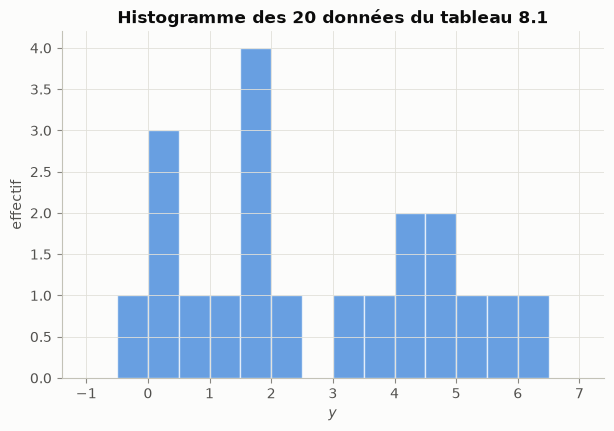

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(y, bins=np.arange(-1, 7.5, 0.5), color=BLUE, alpha=0.7, edgecolor="white")
ax.set(title="Histogramme des 20 données du tableau 8.1", xlabel="$y$", ylabel="effectif")
plt.show()

### Mélange de deux lois normales

On suppose que chaque observation provient de l'un de deux « régimes » :

$$Y_1 \sim N(\mu_1, \sigma_1^2), \qquad Y_2 \sim N(\mu_2, \sigma_2^2), \qquad
Y = (1 - \Delta)\,Y_1 + \Delta\,Y_2, \qquad \text{(éq. (8.36))}$$

où $\Delta \in \{0, 1\}$ est une variable de Bernoulli indépendante, avec
$\Pr(\Delta = 1) = \pi$. Autrement dit : on tire d'abord $\Delta$ (« pile ou face
biaisé »), puis on renvoie $Y_1$ si $\Delta = 0$ et $Y_2$ si $\Delta = 1$.

Notons $\phi_\theta$ la densité de $N(\mu, \sigma^2)$, $\theta = (\mu, \sigma^2)$. Par la
formule des probabilités totales (on conditionne par $\Delta$) :

$$g_Y(y) = (1 - \pi)\,\phi_{\theta_1}(y) + \pi\,\phi_{\theta_2}(y). \qquad
\text{(éq. (8.37))}$$

Illustrons le mécanisme génératif : on simule 2000 valeurs avec des paramètres proches
de ceux que nous estimerons, en coloriant selon la valeur (cachée) de $\Delta$.

In [ ]:
theta_demo = (4.6, 0.8, 1.1, 0.8, 0.55)        # (mu1, var1, mu2, var2, pi)
D = rng.rand(2000) < theta_demo[4]
Ysim = np.where(D, theta_demo[2] + np.sqrt(theta_demo[3]) * rng.randn(2000),
                theta_demo[0] + np.sqrt(theta_demo[1]) * rng.randn(2000))
tt = np.linspace(-2, 8, 400)
fig, ax = plt.subplots(figsize=(7, 4.5))
bins = np.linspace(-2, 8, 60)
ax.hist(Ysim[~D], bins=bins, density=False, color=BLUE, alpha=0.6, label=r"$\Delta = 0$")
ax.hist(Ysim[D], bins=bins, density=False, color=ORANGE, alpha=0.6, label=r"$\Delta = 1$")
ax.set(title="Simulation du mélange (variable latente visible)", xlabel="$y$",
       ylabel="effectif")
ax.legend()
plt.show()

### La log-vraisemblance

Les paramètres sont $\theta = (\pi, \theta_1, \theta_2) = (\pi, \mu_1, \sigma_1^2, \mu_2,
\sigma_2^2)$ (éq. (8.38)) et la log-vraisemblance des $N$ observations vaut

$$\ell(\theta; Z) = \sum_{i=1}^N \log\big[(1 - \pi)\phi_{\theta_1}(y_i) +
\pi\,\phi_{\theta_2}(y_i)\big]. \qquad \text{(éq. (8.39))}$$

La **somme à l'intérieur du logarithme** empêche d'obtenir des formules explicites :
les équations $\partial\ell/\partial\theta = 0$ couplent tous les paramètres.